<a href="https://colab.research.google.com/github/Forello-dev/electroprognosis/blob/main/models/SARIMAX/SARIMAX3.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [23]:
import warnings
warnings.filterwarnings("ignore")

import os
import sys
import importlib
import subprocess
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from statsmodels.tsa.statespace.sarimax import SARIMAX

# --- праздники ---
try:
    import holidays
    RU_HOLIDAYS = holidays.Russia(years=range(2022, 2027))
    def is_holiday(d): return int(d in RU_HOLIDAYS)
except Exception:
    # fallback: фиксированные даты РФ
    _FIXED = {(1,1),(1,2),(1,3),(1,4),(1,5),(1,6),(1,7),(1,8),
              (2,23),(3,8),(5,1),(5,9),(6,12),(11,4)}
    def is_holiday(d): return int((d.month, d.day) in _FIXED)

In [24]:
# =========================================================
# 0. КЛОНИРОВАНИЕ / ЗАГРУЗКА split.py ИЗ GIT-РЕПОЗИТОРИЯ
# =========================================================
SPLIT_REPO   = "https://github.com/Forello-dev/electroprognosis.git"
SPLIT_OWNER  = "Forello-dev"
SPLIT_REPO_N = "electroprognosis"
SPLIT_BRANCH = "main"
SPLIT_FILES  = ["split.py", "src/split.py", "utils/split.py"]  # возможные пути
SPLIT_LOCAL  = "split.py"

def _try_git_clone():
    """Полный git clone (работает и для приватных репо при наличии токена/SSH)."""
    if os.path.isdir(SPLIT_REPO_N):
        return True
    try:
        subprocess.run(
            ["git", "clone", "--depth", "1", SPLIT_REPO, SPLIT_REPO_N],
            check=True, capture_output=True, timeout=120,
        )
        return True
    except Exception as e:
        print(f"[split.py] git clone не удался: {e}")
        return False

def _try_download_raw():
    """Скачивание raw-файла через requests (публичный репо)."""
    try:
        import requests
    except ImportError:
        print("[split.py] requests не установлен — пропускаю raw-загрузку")
        return False

    token = os.environ.get("GITHUB_TOKEN")
    headers = {"Authorization": f"token {token}"} if token else {}

    for path in SPLIT_FILES:
        url = f"https://raw.githubusercontent.com/{SPLIT_OWNER}/{SPLIT_REPO_N}/{SPLIT_BRANCH}/{path}"
        try:
            r = requests.get(url, headers=headers, timeout=30)
            if r.status_code == 200 and "def " in r.text:
                with open(SPLIT_LOCAL, "w", encoding="utf-8") as f:
                    f.write(r.text)
                print(f"[split.py] скачан через raw: {path}")
                return True
        except Exception:
            pass
    return False

def _try_download_api():
    """Скачивание через GitHub Contents API (работает для приватных при токене)."""
    token = os.environ.get("GITHUB_TOKEN")
    if not token:
        return False
    try:
        import requests
        headers = {"Authorization": f"token {token}",
                   "Accept": "application/vnd.github.raw"}
        for path in SPLIT_FILES:
            url = f"https://api.github.com/repos/{SPLIT_OWNER}/{SPLIT_REPO_N}/contents/{path}?ref={SPLIT_BRANCH}"
            r = requests.get(url, headers=headers, timeout=30)
            if r.status_code == 200 and "def " in r.text:
                with open(SPLIT_LOCAL, "w", encoding="utf-8") as f:
                    f.write(r.text)
                print(f"[split.py] скачан через API: {path}")
                return True
    except Exception as e:
        print(f"[split.py] API-загрузка не удалась: {e}")
    return False

def _try_local_clone_copy():
    """Если git clone прошёл — копируем split.py из клонированного репо."""
    if not os.path.isdir(SPLIT_REPO_N):
        return False
    for path in SPLIT_FILES:
        src = os.path.join(SPLIT_REPO_N, path)
        if os.path.isfile(src):
            with open(src, "r", encoding="utf-8") as fi, \
                 open(SPLIT_LOCAL, "w", encoding="utf-8") as fo:
                fo.write(fi.read())
            print(f"[split.py] скопирован из клона: {src}")
            return True
    return False

def _ensure_split_module():
    """Пытается получить split.py; при неудаче создаёт встроенную заглушку."""
    if os.path.isfile(SPLIT_LOCAL):
        print(f"[split.py] найден локально: {SPLIT_LOCAL}")
    else:
        ok = (_try_download_raw()
              or _try_download_api()
              or (_try_git_clone() and _try_local_clone_copy()))
        if not ok:
            print("[split.py] не удалось скачать — использую встроенную реализацию rolling_origin.")
            _write_fallback_split()

    # импорт
    if SPLIT_LOCAL in sys.modules:
        importlib.reload(sys.modules[SPLIT_LOCAL])
    else:
        sys.path.insert(0, os.path.abspath("."))
        importlib.import_module(SPLIT_LOCAL.replace(".py", ""))

def _write_fallback_split():
    """Резервная реализация rolling_origin и forecast_day_indices."""
    code = '''
import numpy as np

def rolling_origin(days, initial_train=365, horizon=1):
    """
    Генератор (i, train_idx) для one-step-ahead rolling origin.
    days       — массив дат (np.datetime64 или datetime)
    initial_train — минимальный размер обучающей выборки (дней)
    horizon    — шаг прогноза (1 = следующий день)
    """
    n = len(days)
    for i in range(initial_train, n, horizon):
        train_idx = np.arange(0, i)          # всё прошлое
        yield i, train_idx

def forecast_day_indices(days, start_date, end_date=None):
    """Индексы дней в диапазоне [start_date, end_date]."""
    days = np.asarray(days)
    mask = days >= np.datetime64(start_date)
    if end_date is not None:
        mask &= days <= np.datetime64(end_date)
    return np.where(mask)[0]
'''
    with open(SPLIT_LOCAL, "w", encoding="utf-8") as f:
        f.write(code)
    print(f"[split.py] создана встроенная реализация: {SPLIT_LOCAL}")

_ensure_split_module()
from split import rolling_origin, forecast_day_indices  # noqa

[split.py] найден локально: split.py


In [25]:
# ========== 1. Загрузка и подготовка ==========
df = pd.read_csv("/content/combined.csv", parse_dates=["date"])
df = df.sort_values("date").reset_index(drop=True)

# Суточные агрегаты: максимум часа (пик) и сумма (для контекста)
df["day"] = df["date"].dt.normalize()
daily = df.groupby("day").agg(
    actual_consumption=("actual_consumption", "max"),   # пик потребления за сутки
    actual_generation=("actual_generation", "max"),    # пик генерации за сутки
    planned_consumption=("planned_consumption", "max"),
    planned_generation=("planned_generation", "max"),
    # средние по дню — как экзогенные признаки
    planned_cons_mean=("planned_consumption", "mean"),
    planned_gen_mean=("planned_generation", "mean"),
    price_mean=("average_price", "mean"),
).reset_index()

# Убираем сутки с нулевыми actual (в данных есть нули/битые значения)
for col in ["actual_consumption", "actual_generation"]:
    daily.loc[daily[col] <= 0, col] = np.nan

In [26]:
# ========== 2. Экзогенные признаки ==========
daily["dow"] = daily["day"].dt.dayofweek
daily["is_weekend"] = (daily["dow"] >= 5).astype(int)
daily["is_holiday"] = daily["day"].apply(is_holiday)
daily["is_dayoff"] = ((daily["is_weekend"] == 1) | (daily["is_holiday"] == 1)).astype(int)
daily["month"] = daily["day"].dt.month
daily["doy"] = daily["day"].dt.dayofyear
daily["t"] = np.arange(len(daily))

# One-hot день недели и месяц
dow_d = pd.get_dummies(daily["dow"], prefix="dow", drop_first=True).astype(int)
mon_d = pd.get_dummies(daily["month"], prefix="mon", drop_first=True).astype(int)
daily = pd.concat([daily, dow_d, mon_d], axis=1)

# Лаг плана (диспетчер публикует план заранее — используем как exog)
daily["planned_cons_lag1"] = daily["planned_consumption"].shift(1)
daily["planned_gen_lag1"]  = daily["planned_generation"].shift(1)
daily["actual_cons_lag1"]  = daily["actual_consumption"].shift(1)
daily["actual_gen_lag1"]   = daily["actual_generation"].shift(1)
daily["actual_cons_lag7"]  = daily["actual_consumption"].shift(7)
daily["actual_gen_lag7"]   = daily["actual_generation"].shift(7)

EXOG_BASE = (
    ["dow_1","dow_2","dow_3","dow_4","dow_5","dow_6",
     "is_weekend","is_holiday","is_dayoff","t"]
    + [f"mon_{m}" for m in range(2, 13)]
)

In [27]:
# ========== 3. Импорт split.py (rolling origin) ==========
# Предполагается, что split.py лежит рядом. Если нет — вставьте его содержимое.
from split import rolling_origin, forecast_day_indices  # noqa

days = daily["day"].values

In [28]:
# ========== 4. Функция прогноза для одной цели ==========
def run_forecast(target, planned_col, exog_extra, order=(1,1,1), seasonal=(0,1,0,7)):
    """
    target: 'actual_consumption' | 'actual_generation'
    planned_col: 'planned_consumption' | 'planned_generation'
    exog_extra: список лаговых признаков, специфичных для цели
    """
    exog_cols = EXOG_BASE + exog_extra + [planned_col]
    # заполнение NaN в лагах
    data = daily.copy()
    for c in exog_cols + [target]:
        data[c] = data[c].astype(float)

    preds, truth, pred_dates, plan_vals = [], [], [], []
    last_success = None

    for i, train_idx in rolling_origin(days):
        # обучающая выборка: строки train_idx
        tr = data.iloc[train_idx]
        # выкидываем сутки без таргета (дырки) и без экзогенных
        tr = tr.dropna(subset=[target] + exog_cols)
        if len(tr) < 60:   # мало данных для сезонной модели
            preds.append(np.nan); truth.append(data[target].iloc[i])
            pred_dates.append(data["day"].iloc[i]); plan_vals.append(data[planned_col].iloc[i])
            continue

        y_tr = tr[target].values
        X_tr = tr[exog_cols].values

        # exog для прогнозируемого дня i
        row = data.iloc[[i]]
        if row[exog_cols].isna().any().any():
            # если лаг пустой (например, первый день) — заполняем ближайшим
            row = row.fillna(method="ffill").fillna(method="bfill")
        X_te = row[exog_cols].values

        try:
            model = SARIMAX(
                y_tr,
                exog=X_tr,
                order=order,
                seasonal_order=seasonal,
                enforce_stationarity=False,
                enforce_invertibility=False,
            )
            res = model.fit(disp=False, maxiter=100)
            y_hat = float(res.forecast(steps=1, exog=X_te)[0])
            last_success = res
        except Exception:
            # fallback: наивный прогноз = лаг1
            y_hat = float(row["actual_cons_lag1"].values[0]
                          if target == "actual_consumption"
                          else row["actual_gen_lag1"].values[0])
            if np.isnan(y_hat):
                y_hat = float(np.nanmean(y_tr[-14:]))

        preds.append(y_hat)
        truth.append(data[target].iloc[i])
        pred_dates.append(data["day"].iloc[i])
        plan_vals.append(data[planned_col].iloc[i])

    res_df = pd.DataFrame({
        "day": pred_dates,
        "actual": truth,
        "pred": preds,
        "planned": plan_vals,
    })
    res_df["resid"] = res_df["actual"] - res_df["pred"]
    return res_df, last_success

In [29]:
# ========== 5. Запуск для consumption и generation ==========
res_cons, _ = run_forecast(
    target="actual_consumption",
    planned_col="planned_consumption",
    exog_extra=["planned_cons_lag1","actual_cons_lag1","actual_cons_lag7","planned_cons_mean"],
)

In [30]:
# ========== 6. Метрики ==========
def metrics(df_res, label):
    d = df_res.dropna(subset=["actual","pred"]).copy()
    if len(d) == 0:
        print(f"[{label}] нет валидных точек"); return
    mae  = mean_absolute_error(d["actual"], d["pred"])
    rmse = np.sqrt(mean_squared_error(d["actual"], d["pred"]))
    r2   = r2_score(d["actual"], d["pred"])
    mape = np.mean(np.abs(d["resid"] / d["actual"])) * 100

    # --- пиковая точность ---
    # 1) hit-rate: доля суток, где прогноз в пределах ±5% реального пика
    within5 = (np.abs(d["resid"]) / d["actual"] <= 0.05).mean() * 100
    within10 = (np.abs(d["resid"]) / d["actual"] <= 0.10).mean() * 100
    # 2) если "пиковые часы" трактовать как сутки с пиком выше 90-го перцентиля
    thr = d["actual"].quantile(0.90)
    peak = d[d["actual"] >= thr]
    peak_mape = np.mean(np.abs(peak["resid"]/peak["actual"]))*100 if len(peak) else np.nan
    peak_within5 = (np.abs(peak["resid"])/peak["actual"] <= 0.05).mean()*100 if len(peak) else np.nan

    print(f"\n=== {label} (n={len(d)} суток) ===")
    print(f"MAE   : {mae:.3f}")
    print(f"RMSE  : {rmse:.3f}")
    print(f"R^2   : {r2:.4f}")
    print(f"MAPE  : {mape:.2f}%")
    print(f"Пиковая точность (hit ±5%): {within5:.1f}%   (±10%: {within10:.1f}%)")
    print(f"MAPE на топ-10% пиковых суток: {peak_mape:.2f}%  (hit ±5%: {peak_within5:.1f}%)")
    return dict(mae=mae, rmse=rmse, r2=r2, mape=mape,
                hit5=within5, hit10=within10,
                peak_mape=peak_mape, peak_hit5=peak_within5)

m_cons = metrics(res_cons, "actual_consumption (пик/сутки)")


=== actual_consumption (пик/сутки) (n=1362 суток) ===
MAE   : 52.859
RMSE  : 65.967
R^2   : 0.9649
MAPE  : 1.17%
Пиковая точность (hit ±5%): 99.9%   (±10%: 100.0%)
MAPE на топ-10% пиковых суток: 1.09%  (hit ±5%: 100.0%)


In [31]:
# ========== 7. Сравнение с наивным прогнозом (лаг-7) — «текущий результат» ==========
# Базлайн: прогноз = значение 7 дней назад (типичная сезонная наивность)
def naive_metrics(res_df, target_lag_col, label):
    d = res_df.merge(
        daily[["day", target_lag_col]].rename(columns={target_lag_col: "naive"}),
        on="day", how="left").dropna(subset=["actual","naive"])
    mae  = mean_absolute_error(d["actual"], d["naive"])
    rmse = np.sqrt(mean_squared_error(d["actual"], d["naive"]))
    r2   = r2_score(d["actual"], d["naive"])
    print(f"\n[Baseline lag-7 | {label}] MAE={mae:.3f}  RMSE={rmse:.3f}  R^2={r2:.4f}")

naive_metrics(res_cons, "actual_cons_lag7", "consumption")


[Baseline lag-7 | consumption] MAE=126.690  RMSE=165.914  R^2=0.7778


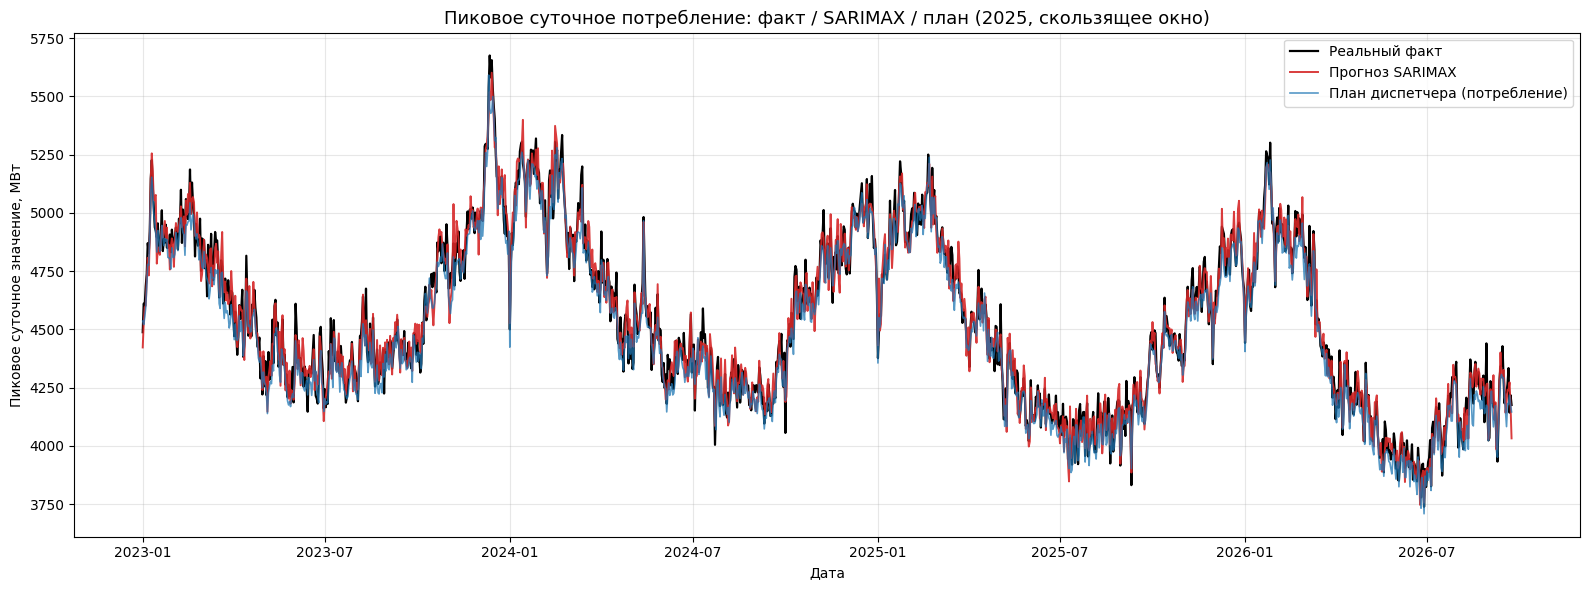

In [32]:
# ========== 8. Визуализация ==========
def plot(res_df, planned_label, title, fname):
    d = res_df.dropna(subset=["actual","pred"]).sort_values("day")
    plt.figure(figsize=(16, 6))
    plt.plot(d["day"], d["actual"],  label="Реальный факт",       lw=1.6, color="black")
    plt.plot(d["day"], d["pred"],    label="Прогноз SARIMAX",    lw=1.4, color="tab:red", alpha=0.9)
    plt.plot(d["day"], d["planned"], label=planned_label,        lw=1.2, color="tab:blue", alpha=0.75)
    plt.title(title, fontsize=13)
    plt.xlabel("Дата"); plt.ylabel("Пиковое суточное значение, МВт")
    plt.legend(loc="best"); plt.grid(alpha=0.3); plt.tight_layout()
    plt.savefig(fname, dpi=130); plt.show()

plot(res_cons, "План диспетчера (потребление)",
     "Пиковое суточное потребление: факт / SARIMAX / план (2025, скользящее окно)",
     "forecast_consumption_2025.png")

In [33]:
res_gen, _ = run_forecast(
    target="actual_generation",
    planned_col="planned_generation",
    exog_extra=["planned_gen_lag1","actual_gen_lag1","actual_gen_lag7","planned_gen_mean"],
)

In [34]:
# ========== 6. Метрики ==========
def metrics(df_res, label):
    d = df_res.dropna(subset=["actual","pred"]).copy()
    if len(d) == 0:
        print(f"[{label}] нет валидных точек"); return
    mae  = mean_absolute_error(d["actual"], d["pred"])
    rmse = np.sqrt(mean_squared_error(d["actual"], d["pred"]))
    r2   = r2_score(d["actual"], d["pred"])
    mape = np.mean(np.abs(d["resid"] / d["actual"])) * 100

    # --- пиковая точность ---
    # 1) hit-rate: доля суток, где прогноз в пределах ±5% реального пика
    within5 = (np.abs(d["resid"]) / d["actual"] <= 0.05).mean() * 100
    within10 = (np.abs(d["resid"]) / d["actual"] <= 0.10).mean() * 100
    # 2) если "пиковые часы" трактовать как сутки с пиком выше 90-го перцентиля
    thr = d["actual"].quantile(0.90)
    peak = d[d["actual"] >= thr]
    peak_mape = np.mean(np.abs(peak["resid"]/peak["actual"]))*100 if len(peak) else np.nan
    peak_within5 = (np.abs(peak["resid"])/peak["actual"] <= 0.05).mean()*100 if len(peak) else np.nan

    print(f"\n=== {label} (n={len(d)} суток) ===")
    print(f"MAE   : {mae:.3f}")
    print(f"RMSE  : {rmse:.3f}")
    print(f"R^2   : {r2:.4f}")
    print(f"MAPE  : {mape:.2f}%")
    print(f"Пиковая точность (hit ±5%): {within5:.1f}%   (±10%: {within10:.1f}%)")
    print(f"MAPE на топ-10% пиковых суток: {peak_mape:.2f}%  (hit ±5%: {peak_within5:.1f}%)")
    return dict(mae=mae, rmse=rmse, r2=r2, mape=mape,
                hit5=within5, hit10=within10,
                peak_mape=peak_mape, peak_hit5=peak_within5)

m_gen  = metrics(res_gen,  "actual_generation (пик/сутки)")


=== actual_generation (пик/сутки) (n=1362 суток) ===
MAE   : 41.751
RMSE  : 70.028
R^2   : 0.9737
MAPE  : 1.36%
Пиковая точность (hit ±5%): 95.5%   (±10%: 99.0%)
MAPE на топ-10% пиковых суток: 1.26%  (hit ±5%: 94.2%)


In [35]:
# ========== 7. Сравнение с наивным прогнозом (лаг-7) — «текущий результат» ==========
# Базлайн: прогноз = значение 7 дней назад (типичная сезонная наивность)
def naive_metrics(res_df, target_lag_col, label):
    d = res_df.merge(
        daily[["day", target_lag_col]].rename(columns={target_lag_col: "naive"}),
        on="day", how="left").dropna(subset=["actual","naive"])
    mae  = mean_absolute_error(d["actual"], d["naive"])
    rmse = np.sqrt(mean_squared_error(d["actual"], d["naive"]))
    r2   = r2_score(d["actual"], d["naive"])
    print(f"\n[Baseline lag-7 | {label}] MAE={mae:.3f}  RMSE={rmse:.3f}  R^2={r2:.4f}")

naive_metrics(res_gen,  "actual_gen_lag7",  "generation")


[Baseline lag-7 | generation] MAE=240.449  RMSE=314.194  R^2=0.4706


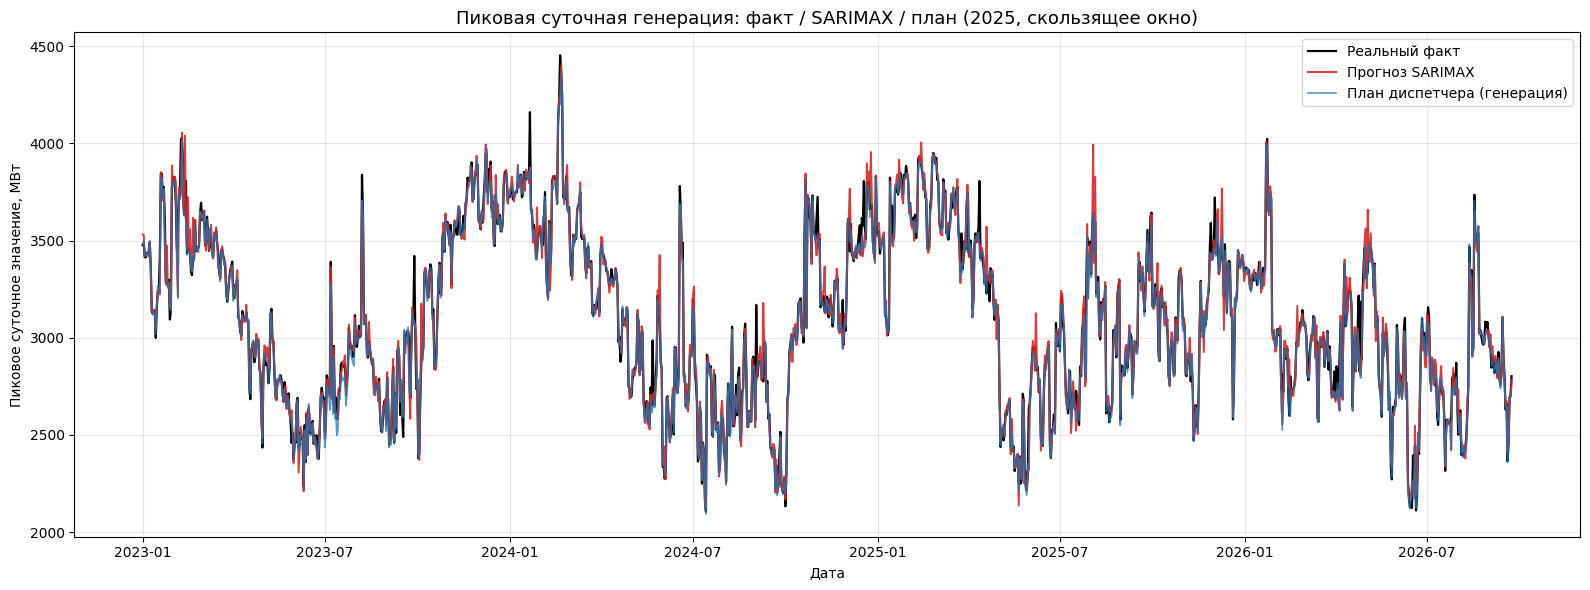

In [36]:
# ========== 8. Визуализация ==========
def plot(res_df, planned_label, title, fname):
    d = res_df.dropna(subset=["actual","pred"]).sort_values("day")
    plt.figure(figsize=(16, 6))
    plt.plot(d["day"], d["actual"],  label="Реальный факт",       lw=1.6, color="black")
    plt.plot(d["day"], d["pred"],    label="Прогноз SARIMAX",    lw=1.4, color="tab:red", alpha=0.9)
    plt.plot(d["day"], d["planned"], label=planned_label,        lw=1.2, color="tab:blue", alpha=0.75)
    plt.title(title, fontsize=13)
    plt.xlabel("Дата"); plt.ylabel("Пиковое суточное значение, МВт")
    plt.legend(loc="best"); plt.grid(alpha=0.3); plt.tight_layout()
    plt.savefig(fname, dpi=130); plt.show()

plot(res_gen, "План диспетчера (генерация)",
     "Пиковая суточная генерация: факт / SARIMAX / план (2025, скользящее окно)",
     "forecast_generation_2025.png")

In [64]:
from __future__ import annotations

import numpy as np
import pandas as pd
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score


# ---------- внутренняя логика выбора пиковых точек ----------

def _pick_peak_mask(df: pd.DataFrame, actual_col: str, mode: str,
                    top_n: int, q: float, window: tuple[int, int]) -> pd.Series:
    """
    Возвращает булев Series той же длины, что df, — True там, где "пиковый час".
    df должен содержать колонку времени (date или day).
    """
    if mode == "daily_peak":
        # один пик на сутки
        t = pd.to_datetime(df["date"] if "date" in df.columns else df["day"])
        if t.dt.hour.nunique() == 1 and len(df) == t.dt.normalize().nunique():
            # данные уже суточные — все точки "пиковые"
            return pd.Series(True, index=df.index)
        idx = df.groupby(t.dt.normalize())[actual_col].idxmax()
        mask = pd.Series(False, index=df.index)
        mask.loc[idx] = True
        return mask

    if mode == "top_hours_daily":
        t = pd.to_datetime(df["date"])
        if t.dt.hour.nunique() == 1:
            # суточные данные — вырождается в daily_peak
            return _pick_peak_mask(df, actual_col, "daily_peak", top_n, q, window)
        ranks = df.groupby(t.dt.normalize())[actual_col].rank(method="first", ascending=False)
        return ranks <= top_n

    if mode == "threshold_hours":
        thr = df[actual_col].quantile(q)
        return df[actual_col] >= thr

    if mode == "window":
        if "date" not in df.columns:
            # суточные данные — окно не применимо
            return _pick_peak_mask(df, actual_col, "daily_peak", top_n, q, window)
        h = pd.to_datetime(df["date"]).dt.hour
        lo, hi = window
        return (h >= lo) & (h <= hi)

    raise ValueError(f"unknown mode={mode!r}")


# ---------- 1. Hit-rate на пиковых часах ----------

def peak_hit_rate(df: pd.DataFrame, actual_col="actual", pred_col="pred",
                  mode="daily_peak", top_n=5, q=0.90, window=(17, 21),
                  tol=0.05) -> float:
    """% пиковых часов, где прогноз в пределах ±tol от факта."""
    mask = _pick_peak_mask(df, actual_col, mode, top_n, q, window)
    if mask.sum() == 0:
        return np.nan
    a = df.loc[mask, actual_col].astype(float)
    p = df.loc[mask, pred_col].astype(float)
    ok = (np.abs(p - a) / np.where(a == 0, np.nan, a)).fillna(0) <= tol
    return float(ok.mean() * 100)


# ---------- 2. MAPE на пиковых часах ----------

def peak_mape(df: pd.DataFrame, actual_col="actual", pred_col="pred",
              mode="daily_peak", top_n=5, q=0.90, window=(17, 21)) -> float:
    """MAPE (%), посчитанный ТОЛЬКО на пиковых часах."""
    mask = _pick_peak_mask(df, actual_col, mode, top_n, q, window)
    if mask.sum() == 0:
        return np.nan
    a = df.loc[mask, actual_col].astype(float)
    p = df.loc[mask, pred_col].astype(float)
    return float(np.mean(np.abs((p - a) / a)) * 100)


# ---------- 3. Precision / Recall / F1 для класса "пик" ----------

def peak_precision_recall(df: pd.DataFrame, actual_col="actual", pred_col="pred",
                          mode="daily_peak", top_n=5, q=0.90, window=(17, 21),
                          pred_quantile: float | None = None) -> dict:
    """
    Сравнивает "истинно пиковые" (по факту) и "предсказанно пиковые" (по прогнозу).

    pred_quantile: если None — берётся та же доля, что у фактических пиков
                   (напр., если пиков 5% точек, то и прогноз порогуем по 95-му
                   перцентилю прогноза). Если задан — фиксированный квантиль.
    """
    true_mask = _pick_peak_mask(df, actual_col, mode, top_n, q, window)
    if true_mask.sum() == 0:
        return {"precision": np.nan, "recall": np.nan, "f1": np.nan}

    # доля пиков среди всех точек
    frac = true_mask.mean()
    if pred_quantile is None:
        # порог по прогнозу, дающий такую же долю точек
        pred_thr = df[pred_col].astype(float).quantile(1 - frac)
    else:
        pred_thr = df[pred_col].astype(float).quantile(pred_quantile)
    pred_mask = df[pred_col].astype(float) >= pred_thr

    tp = int((true_mask & pred_mask).sum())
    fp = int((~true_mask & pred_mask).sum())
    fn = int((true_mask & ~pred_mask).sum())
    precision = tp / (tp + fp) * 100 if (tp + fp) else np.nan
    recall    = tp / (tp + fn) * 100 if (tp + fn) else np.nan
    f1 = (2 * precision * recall / (precision + recall)) if (precision + recall) else np.nan
    return {"precision": precision, "recall": recall, "f1": f1,
            "tp": tp, "fp": fp, "fn": fn}


# ---------- 4. Полный отчёт ----------

def peak_report(df: pd.DataFrame, actual_col="actual", pred_col="pred",
                modes=("daily_peak", "threshold_hours", "top_hours_daily", "window"),
                top_n=5, q=0.90, window=(17, 21), tol=0.05,
                label: str = "peak", verbose: bool = True) -> dict:
    """
    Считает базовые метрики + пиковые метрики по всем режимам.
    Возвращает словарь со всеми значениями.
    """
    d = df.dropna(subset=[actual_col, pred_col]).copy()
    out = {"label": label, "n_points": len(d)}

    # базовые
    a, p = d[actual_col].astype(float), d[pred_col].astype(float)
    out["MAE"]  = float(mean_absolute_error(a, p))
    out["RMSE"] = float(np.sqrt(mean_squared_error(a, p)))
    out["R2"]   = float(r2_score(a, p))
    out["MAPE"] = float(np.mean(np.abs((p - a) / a)) * 100)

    # пиковые по режимам
    for m in modes:
        key = m
        hit  = peak_hit_rate(d, actual_col, pred_col, mode=m,
                             top_n=top_n, q=q, window=window, tol=tol)
        pmape = peak_mape(d, actual_col, pred_col, mode=m,
                          top_n=top_n, q=q, window=window)
        pr = peak_precision_recall(d, actual_col, pred_col, mode=m,
                                   top_n=top_n, q=q, window=window)
        out[f"{key}_hit5"]      = hit
        out[f"{key}_MAPE"]      = pmape
        out[f"{key}_precision"] = pr["precision"]
        out[f"{key}_recall"]    = pr["recall"]
        out[f"{key}_F1"]        = pr["f1"]

    if verbose:
        print(f"\n=== {label} | n={out['n_points']} точек ===")
        print(f"MAE={out['MAE']:.3f}  RMSE={out['RMSE']:.3f}  "
              f"R^2={out['R2']:.4f}  MAPE={out['MAPE']:.2f}%")
        print(f"{'режим':<18}{'hit@5%':>9}{'MAPE':>9}{'Prec':>9}{'Rec':>9}{'F1':>9}")
        for m in modes:
            print(f"{m:<18}"
                  f"{out[f'{m}_hit5']:>8.1f}%"
                  f"{out[f'{m}_MAPE']:>8.2f}%"
                  f"{out[f'{m}_precision']:>8.1f}%"
                  f"{out[f'{m}_recall']:>8.1f}%"
                  f"{out[f'{m}_F1']:>8.1f}%")
    return out

# --- почасовой вариант (рекомендуется) ---
# собираем почасовой DataFrame для 2025 с прогнозами.
# Если прогноз строился на суточных пиках, нужно "раскатать" его обратно
# на час пика каждого дня; проще всего — сравнить пики напрямую (daily_peak).
# Ниже — оба варианта.

# A) Сравнение на суточных пиках (как в основном коде):
m_cons_peak = peak_report(
    res_cons.rename(columns={"actual":"actual", "pred":"pred"}),
    modes=("daily_peak",), label="consumption | пик/сутки",
)
m_gen_peak = peak_report(
    res_gen.rename(columns={"actual":"actual", "pred":"pred"}),
    modes=("daily_peak",), label="generation | пик/сутки",
)
print("\n")
peak_report(res_cons, modes=("daily_peak",), label="consumption | суточный пик")
peak_report(res_gen,  modes=("daily_peak",), label="generation | суточный пик")
res_cons.info()


=== consumption | пик/сутки | n=1362 точек ===
MAE=52.859  RMSE=65.967  R^2=0.9649  MAPE=1.17%
режим                hit@5%     MAPE     Prec      Rec       F1
daily_peak            99.9%    1.17%   100.0%   100.0%   100.0%

=== generation | пик/сутки | n=1362 точек ===
MAE=41.751  RMSE=70.028  R^2=0.9737  MAPE=1.36%
режим                hit@5%     MAPE     Prec      Rec       F1
daily_peak            95.5%    1.36%   100.0%   100.0%   100.0%



=== consumption | суточный пик | n=1362 точек ===
MAE=52.859  RMSE=65.967  R^2=0.9649  MAPE=1.17%
режим                hit@5%     MAPE     Prec      Rec       F1
daily_peak            99.9%    1.17%   100.0%   100.0%   100.0%

=== generation | суточный пик | n=1362 точек ===
MAE=41.751  RMSE=70.028  R^2=0.9737  MAPE=1.36%
режим                hit@5%     MAPE     Prec      Rec       F1
daily_peak            95.5%    1.36%   100.0%   100.0%   100.0%
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1362 entries, 0 to 1361
Data columns (total 5 co

In [77]:
import pandas as pd

d = res_cons.dropna(subset=["actual", "pred"]).copy()

# ограничим 2025 годом (на случай, если в res_cons есть другие годы)
d = d[(d["day"] >= pd.Timestamp("2025-01-01")) &
      (d["day"] <= pd.Timestamp("2025-12-31"))]

# относительная ошибка по каждому дню
rel_err = (d["pred"] - d["actual"]).abs() / d["actual"]

# 1) доля суток, где прогноз в пределах ±5% реального пика
hit5 = (rel_err <= 0.05).mean() * 100

# 2) MAPE — средняя относительная ошибка (чем меньше, тем лучше)
mape = rel_err.mean() * 100

# 3) "точность" = 100% − MAPE (простая интерпретация «в среднем угадали на X%»)
accuracy = 100.0 - mape

print(f"Суток: {len(d)}")
print(f"Точность (hit ±5%): {hit5:.2f}%")
print(f"MAPE: {mape:.2f}%")
print(f"Точность (100% − MAPE): {accuracy:.2f}%")


Суток: 365
Точность (hit ±5%): 99.73%
MAPE: 1.08%
Точность (100% − MAPE): 98.92%


In [79]:
import pandas as pd

df["day"] = df["date"].dt.normalize()

# сопоставляем почасовой df с суточным res_cons по дню
df_cons = df[["day", "date", "actual_consumption"]].merge(
    res_cons[["day", "pred"]], on="day", how="inner"
)

# ограничим 2025 годом
df_cons = df_cons[
    (df_cons["day"] >= pd.Timestamp("2025-01-01")) &
    (df_cons["day"] <= pd.Timestamp("2025-12-31"))
].copy()

# "прогнозный уровень" в каждом часу: отклонение факта от суточного pred
df_cons["dist"] = (df_cons["actual_consumption"] - df_cons["pred"]).abs()

def topn_hit(df_cons, n):
    hits, total = 0, 0
    for d, g in df_cons.groupby("day"):
        g_true = g.nlargest(n, "actual_consumption")
        g_pred = g.nsmallest(n, "dist")   # ближе всего к прогнозу = "прогнозный пик"
        s_true = set(g_true["date"].dt.hour)
        s_pred = set(g_pred["date"].dt.hour)
        hits  += len(s_true & s_pred)
        total += n
    return 100.0 * hits / total if total else float("nan")

for n in (1, 3, 5):
    acc = topn_hit(df_cons, n)
    print(f"top{n}: {acc:.2f}%")

top1: 61.37%
top3: 85.48%
top5: 94.08%


In [80]:
import pandas as pd

df["day"] = df["date"].dt.normalize()

# сопоставляем почасовой df с суточным res_gen по дню
df_gen = df[["day", "date", "actual_generation"]].merge(
    res_gen[["day", "pred"]], on="day", how="inner"
)

# ограничим 2025 годом
df_gen = df_gen[
    (df_gen["day"] >= pd.Timestamp("2025-01-01")) &
    (df_gen["day"] <= pd.Timestamp("2025-12-31"))
].copy()

# "прогнозный уровень" в каждом часу: отклонение факта от суточного pred
df_gen["dist"] = (df_gen["actual_generation"] - df_gen["pred"]).abs()

def topn_hit(df_gen, n):
    hits, total = 0, 0
    for d, g in df_gen.groupby("day"):
        g_true = g.nlargest(n, "actual_generation")
        g_pred = g.nsmallest(n, "dist")   # ближе всего к прогнозу = "прогнозный пик"
        s_true = set(g_true["date"].dt.hour)
        s_pred = set(g_pred["date"].dt.hour)
        hits  += len(s_true & s_pred)
        total += n
    return 100.0 * hits / total if total else float("nan")

for n in (1, 3, 5):
    acc = topn_hit(df_gen, n)
    print(f"generation top{n}: {acc:.2f}%")

generation top1: 56.16%
generation top3: 68.58%
generation top5: 76.88%


In [84]:
import pandas as pd

df["day"] = df["date"].dt.normalize()

# сопоставляем почасовой df с суточным res_cons по дню
df_plan = df[["day", "date", "planned_consumption"]].merge(
    res_cons[["day", "pred"]], on="day", how="inner"
)

# ограничим 2025 годом
df_plan = df_plan[
    (df_plan["day"] >= pd.Timestamp("2025-01-01")) &
    (df_plan["day"] <= pd.Timestamp("2025-12-31"))
].copy()

# "прогнозный уровень" в каждом часу: отклонение плана от суточного pred
df_plan["dist"] = (df_plan["planned_consumption"] - df_plan["pred"]).abs()

def topn_hit(df_plan, n):
    hits, total = 0, 0
    for d, g in df_plan.groupby("day"):
        g_true = g.nlargest(n, "planned_consumption")   # топ-N часов по плану
        g_pred = g.nsmallest(n, "dist")                 # ближе всего к прогнозу
        s_true = set(g_true["date"].dt.hour)
        s_pred = set(g_pred["date"].dt.hour)
        hits  += len(s_true & s_pred)
        total += n
    return 100.0 * hits / total if total else float("nan")

for n in (1, 3, 5):
    acc = topn_hit(df_plan, n)
    print(f"planned_consumption top{n}: {acc:.2f}%")

planned_consumption top1: 81.37%
planned_consumption top3: 93.61%
planned_consumption top5: 97.59%


In [86]:
import pandas as pd

df["day"] = df["date"].dt.normalize()

# сопоставляем почасовой df с суточным res_gen по дню
df_plan_gen = df[["day", "date", "planned_generation"]].merge(
    res_gen[["day", "pred"]], on="day", how="inner"
)

# ограничим 2025 годом
df_plan_gen = df_plan_gen[
    (df_plan_gen["day"] >= pd.Timestamp("2025-01-01")) &
    (df_plan_gen["day"] <= pd.Timestamp("2025-12-31"))
].copy()

# "прогнозный уровень" в каждом часу: отклонение плана от суточного pred
df_plan_gen["dist"] = (df_plan_gen["planned_generation"] - df_plan_gen["pred"]).abs()

def topn_hit(df_plan_gen, n):
    hits, total = 0, 0
    for d, g in df_plan_gen.groupby("day"):
        g_true = g.nlargest(n, "planned_generation")   # топ-N часов по плану генерации
        g_pred = g.nsmallest(n, "dist")                # ближе всего к прогнозу
        s_true = set(g_true["date"].dt.hour)
        s_pred = set(g_pred["date"].dt.hour)
        hits  += len(s_true & s_pred)
        total += n
    return 100.0 * hits / total if total else float("nan")

for n in (1, 3, 5):
    acc = topn_hit(df_plan_gen, n)
    print(f"planned_generation top{n}: {acc:.2f}%")

planned_generation top1: 70.41%
planned_generation top3: 80.46%
planned_generation top5: 84.93%
